# Data Sanity Checks

Verification that the loaded NHL data is correct, complete, and trustworthy
**before** building models on it. Re-run this notebook after any data pull.

**Sections**
1. Setup
2. Row counts & per-season coverage
3. Team coverage (home/away balance)
4. Shot coordinate distributions  *(highest-value visual check)*
5. Goals reconcile with final scores  *(highest-value correctness check)*
6. NULL rates on model-critical columns
7. Single known-game deep dive

The division of labor: sections 2–3 confirm the data is *present and complete*,
4–6 confirm it is *internally consistent*, and 7 confirms it *matches external reality*.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "..")  # notebook lives in notebooks/, project root is one level up

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data.db import get_connection, get_shots_for_game

conn = get_connection()
pd.set_option("display.max_columns", None)
print("Connected.")

Connected.


## 2. Row counts & per-season coverage

Confirm every table is populated and the per-season game counts look right
(~1,312 games per full regular season).

In [2]:
tables = ["teams", "players", "schedule", "games", "skater_game_stats",
          "goalie_game_stats", "shot_events", "shifts"]

counts = {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables}
pd.DataFrame.from_dict(counts, orient="index", columns=["rows"])

,rows
teams,32
players,876
schedule,6560
games,6560
skater_game_stats,236101
goalie_game_stats,26238
shot_events,773259
shifts,4578542


In [3]:
# Games + shots per season, with shots-per-game derived
season_summary = pd.read_sql('''
    SELECT
        g.season,
        COUNT(DISTINCT g.id)                       AS games,
        COUNT(s.event_id)                          AS shot_events,
        ROUND(COUNT(s.event_id) * 1.0 / COUNT(DISTINCT g.id), 1) AS shots_per_game
    FROM games g
    LEFT JOIN shot_events s ON s.game_id = g.id
    GROUP BY g.season
    ORDER BY g.season
''', conn)
season_summary

,season,games,shot_events,shots_per_game
0,20212022,1312,149412,113.9
1,20222023,1312,153348,116.9
2,20232024,1312,160123,122.0
3,20242025,1312,156622,119.4
4,20252026,1312,153754,117.2


In [4]:
# What's the most recent game in the data? (sanity on date coverage)
latest = conn.execute("SELECT MAX(game_date) FROM games").fetchone()[0]
earliest = conn.execute("SELECT MIN(game_date) FROM games").fetchone()[0]
print(f"Game date range: {earliest}  ->  {latest}")

Game date range: 2021-10-12  ->  2026-04-16


## 3. Team coverage (home/away balance)

Every team should have a roughly equal total number of games, and home games
should be ~50% of each team's total. A team with a lopsided home/away split or a
suspiciously low total points to a parsing or filtering problem.

In [5]:
home = pd.read_sql(
    "SELECT home_team_abbrev AS team, COUNT(*) AS home_games FROM games GROUP BY home_team_abbrev",
    conn).set_index("team")
away = pd.read_sql(
    "SELECT away_team_abbrev AS team, COUNT(*) AS away_games FROM games GROUP BY away_team_abbrev",
    conn).set_index("team")

balance = home.join(away)
balance["total"] = balance.home_games + balance.away_games
balance["home_pct"] = (balance.home_games / balance.total).round(3)
balance = balance.sort_values("total")
print(f"Teams: {len(balance)}")
print(f"Total range: {balance.total.min()} - {balance.total.max()}")
print(f"home_pct range: {balance.home_pct.min():.3f} - {balance.home_pct.max():.3f}")
balance

Teams: 33
Total range: 164 - 410
home_pct range: 0.500 - 0.500


,home_games,away_games,total,home_pct
team,,,,
UTA,82,82,164,0.5
ARI,123,123,246,0.5
BOS,205,205,410,0.5
ANA,205,205,410,0.5
CAR,205,205,410,0.5
CBJ,205,205,410,0.5
CGY,205,205,410,0.5
BUF,205,205,410,0.5
COL,205,205,410,0.5


## 4. Shot coordinate distributions  *(highest-value visual check)*

The single most informative check. Load every shot with coordinates and look at
where they land.

**What healthy data looks like:** two symmetric clusters (the NHL records shots
from both ends, so raw x spans roughly -100 to +100), density concentrated in
front of each net, thinning toward the blue lines, near-empty at center ice.

**Red flags:**
- A spike at exactly (0, 0) -> missing coords stored as zero instead of NULL
- Strong left/right asymmetry -> home/away coordinate-flip bug
- Points outside +/-100 (x) or +/-42.5 (y) -> units / scaling problem

In [6]:
shots = pd.read_sql('''
    SELECT x_coord, y_coord, event_type, team_id
    FROM shot_events
    WHERE x_coord IS NOT NULL AND y_coord IS NOT NULL
''', conn)

print(f"Shots with coordinates: {len(shots):,}")
print(f"x range: [{shots.x_coord.min():.0f}, {shots.x_coord.max():.0f}]")
print(f"y range: [{shots.y_coord.min():.0f}, {shots.y_coord.max():.0f}]")

# Check for the (0,0) spike specifically
at_origin = ((shots.x_coord == 0) & (shots.y_coord == 0)).sum()
print(f"Shots at exactly (0, 0): {at_origin:,}  "
      f"({at_origin / len(shots):.2%}) -- should be near zero")

Shots with coordinates: 773,259
x range: [-99, 99]
y range: [-42, 42]
Shots at exactly (0, 0): 19  (0.00%) -- should be near zero


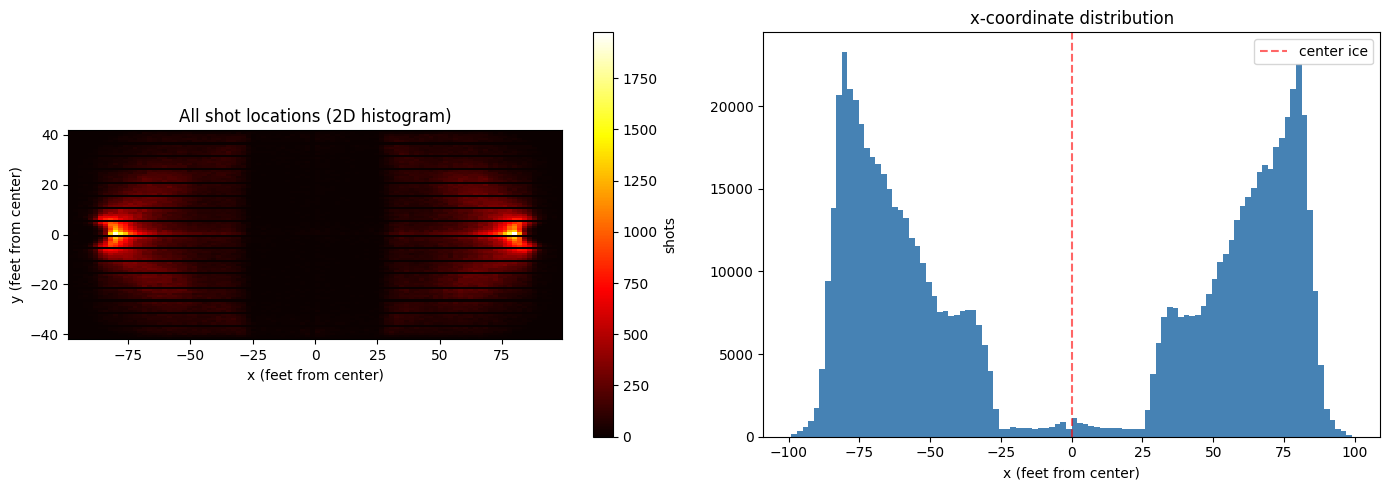

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2D histogram of all shot locations
h = axes[0].hist2d(shots.x_coord, shots.y_coord, bins=100, cmap="hot")
axes[0].set_title("All shot locations (2D histogram)")
axes[0].set_xlabel("x (feet from center)")
axes[0].set_ylabel("y (feet from center)")
axes[0].set_aspect("equal")
fig.colorbar(h[3], ax=axes[0], label="shots")

# Marginal x distribution (should be roughly bimodal & symmetric)
axes[1].hist(shots.x_coord, bins=100, color="steelblue")
axes[1].axvline(0, color="red", linestyle="--", alpha=0.6, label="center ice")
axes[1].set_title("x-coordinate distribution")
axes[1].set_xlabel("x (feet from center)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Goals reconcile with final scores  *(highest-value correctness check)*

For a sample of games, count `goal` events in `shot_events` and compare to the
official `home_score` / `away_score` in the `games` table. If these disagree,
something is wrong with how goals are recorded or attributed -- which would
poison both the xG model (mislabeled outcomes) and the game model (wrong counts).

**Expected quirk:** shootout-decided games. The official score includes one
shootout-winner goal that does *not* appear as a normal `goal` event in
play-by-play. So expect a small number of off-by-one mismatches that cluster on
one-goal-margin games. That's the shootout signature, not a bug -- but this check
is how you learn to recognize it.

In [8]:
# Count goal events per (game, team)
goal_events = pd.read_sql('''
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal'
    GROUP BY game_id, team_id
''', conn)

# Official scores + team ids, joined from games + schedule
games = pd.read_sql('''
    SELECT g.id AS game_id, g.home_score, g.away_score,
           g.home_team_abbrev, g.away_team_abbrev,
           sc.home_team_id, sc.away_team_id
    FROM games g
    JOIN schedule sc ON sc.game_id = g.id
''', conn)

# Build quick lookup: (game_id, team_id) -> goal count
goal_lookup = {(r.game_id, r.team_id): r.goals_in_events
               for r in goal_events.itertuples()}

def event_goals(game_id, team_id):
    return goal_lookup.get((game_id, team_id), 0)

# Sample for speed (vectorize later if it looks clean)
sample = games.sample(min(300, len(games)), random_state=42).copy()
sample["event_home_goals"] = [event_goals(r.game_id, r.home_team_id) for r in sample.itertuples()]
sample["event_away_goals"] = [event_goals(r.game_id, r.away_team_id) for r in sample.itertuples()]
sample["home_match"] = sample.home_score == sample.event_home_goals
sample["away_match"] = sample.away_score == sample.event_away_goals
sample["full_match"] = sample.home_match & sample.away_match

mismatch_rate = 1 - sample.full_match.mean()
print(f"Sampled games: {len(sample)}")
print(f"Full-match rate: {sample.full_match.mean():.1%}")
print(f"Mismatch rate:   {mismatch_rate:.1%}")

Sampled games: 300
Full-match rate: 96.7%
Mismatch rate:   3.3%


In [9]:
# Inspect mismatches. Margin == 1 on the official score is the shootout signature.
mism = sample[~sample.full_match].copy()
mism["off_by"] = (
    (mism.home_score - mism.event_home_goals).abs()
    + (mism.away_score - mism.event_away_goals).abs()
)
mism["score_margin"] = (mism.home_score - mism.away_score).abs()
print(f"Mismatches: {len(mism)}")
if len(mism):
    print(f"  ...of which off-by-exactly-1: {(mism.off_by == 1).sum()} "
          f"(likely shootouts)")
mism[["game_id", "home_team_abbrev", "home_score", "event_home_goals",
      "away_team_abbrev", "away_score", "event_away_goals",
      "off_by", "score_margin"]].head(20)

Mismatches: 10
  ...of which off-by-exactly-1: 2 (likely shootouts)


,game_id,home_team_abbrev,home_score,event_home_goals,away_team_abbrev,away_score,event_away_goals,off_by,score_margin
6050,2025020803,CHI,1,3,TBL,2,4,4,1
233,2021020234,NJD,2,3,OTT,3,4,2,1
4783,2024020848,PIT,2,4,NJD,3,5,4,1
5400,2025020153,FLA,2,3,ANA,3,4,2,1
3352,2023020729,LAK,3,3,SJS,4,5,1,1
2883,2023020260,CGY,4,5,NYI,5,6,2,1
4160,2024020225,FLA,4,5,PHI,3,4,2,1
604,2021020605,DAL,6,7,FLA,5,5,1,1
4649,2024020714,NSH,3,5,CHI,2,3,3,1
5899,2025020652,WSH,2,4,CHI,3,5,4,1


In [10]:
# How many events live in period 5 (shootout) and what types are they?
print("Events by period:")
print(pd.read_sql("""
    SELECT period, event_type, COUNT(*) AS n
    FROM shot_events
    WHERE period >= 4
    GROUP BY period, event_type
    ORDER BY period, n DESC
""", conn).to_string(index=False))

# How many 'goal' events are in the shootout specifically?
so_goals = conn.execute(
    "SELECT COUNT(*) FROM shot_events WHERE period = 5 AND event_type = 'goal'"
).fetchone()[0]
total_goals = conn.execute(
    "SELECT COUNT(*) FROM shot_events WHERE event_type = 'goal'"
).fetchone()[0]
print(f"\nShootout 'goals': {so_goals:,} of {total_goals:,} total "
      f"({so_goals/total_goals:.1%})")

# Re-run the reconciliation EXCLUDING period 5, see if mismatch drops
goal_events_no_so = pd.read_sql("""
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal' AND period < 5
    GROUP BY game_id, team_id
""", conn)
print(f"\nRe-run reconciliation with period < 5 filter to confirm match rate improves.")

Events by period:
 period   event_type    n
      4 shot-on-goal 4596
      4  missed-shot 1937
      4 blocked-shot 1521
      4         goal  984
      5 shot-on-goal 1673
      5         goal 1065
      5  missed-shot  566

Shootout 'goals': 1,065 of 41,536 total (2.6%)

Re-run reconciliation with period < 5 filter to confirm match rate improves.


In [11]:
# Reconciliation, this time excluding shootout (period 5) goal events
goal_events_clean = pd.read_sql('''
    SELECT game_id, team_id, COUNT(*) AS goals_in_events
    FROM shot_events
    WHERE event_type = 'goal' AND period < 5
    GROUP BY game_id, team_id
''', conn)

goal_lookup_clean = {(r.game_id, r.team_id): r.goals_in_events
                     for r in goal_events_clean.itertuples()}

def event_goals_clean(game_id, team_id):
    return goal_lookup_clean.get((game_id, team_id), 0)

# Reuse the same 300-game sample for an apples-to-apples comparison
sample["event_home_goals_clean"] = [
    event_goals_clean(r.game_id, r.home_team_id) for r in sample.itertuples()
]
sample["event_away_goals_clean"] = [
    event_goals_clean(r.game_id, r.away_team_id) for r in sample.itertuples()
]
sample["full_match_clean"] = (
    (sample.home_score == sample.event_home_goals_clean)
    & (sample.away_score == sample.event_away_goals_clean)
)

print(f"Match rate WITH shootout goals:    {sample.full_match.mean():.1%}")
print(f"Match rate WITHOUT shootout goals: {sample.full_match_clean.mean():.1%}")

# Inspect any remaining mismatches — should be off-by-1 shootout-winner credits
resid = sample[~sample.full_match_clean].copy()
resid["off_by"] = (
    (resid.home_score - resid.event_home_goals_clean).abs()
    + (resid.away_score - resid.event_away_goals_clean).abs()
)
print(f"\nRemaining mismatches: {len(resid)}")
if len(resid):
    print(f"  off-by-exactly-1: {(resid.off_by == 1).sum()} (expected shootout-winner credit)")
    print(f"  off-by-more-than-1: {(resid.off_by > 1).sum()} (investigate if nonzero)")

Match rate WITH shootout goals:    96.7%
Match rate WITHOUT shootout goals: 94.7%

Remaining mismatches: 16
  off-by-exactly-1: 16 (expected shootout-winner credit)
  off-by-more-than-1: 0 (investigate if nonzero)


## 6. NULL rates on model-critical columns

How much of the data is actually usable for the xG model. Some NULL coordinate
rate is expected and legitimate -- blocked shots have no recordable shot location.
You want to *know* the number so you can decide how to filter, and so a 40% rate
(a real problem) doesn't hide behind an assumed 15% (just blocked shots).

In [12]:
null_checks = pd.read_sql('''
    SELECT
        COUNT(*) AS total,
        SUM(CASE WHEN x_coord IS NULL THEN 1 ELSE 0 END)            AS null_x,
        SUM(CASE WHEN y_coord IS NULL THEN 1 ELSE 0 END)            AS null_y,
        SUM(CASE WHEN shot_type IS NULL THEN 1 ELSE 0 END)          AS null_shot_type,
        SUM(CASE WHEN shooting_player_id IS NULL THEN 1 ELSE 0 END) AS null_shooter
    FROM shot_events
''', conn)

total = null_checks.total.iloc[0]
print(f"Total shot events: {total:,}\n")
for col in ["null_x", "null_y", "null_shot_type", "null_shooter"]:
    n = null_checks[col].iloc[0]
    print(f"  {col:18s}: {n:>8,}  ({n/total:.1%})")

# Breakdown by event_type: blocked shots are the expected source of NULL coords
print("\nNULL-coordinate rate by event_type:")
by_type = pd.read_sql('''
    SELECT event_type,
           COUNT(*) AS n,
           SUM(CASE WHEN x_coord IS NULL THEN 1 ELSE 0 END) AS null_coords
    FROM shot_events
    GROUP BY event_type
    ORDER BY n DESC
''', conn)
by_type["null_pct"] = (by_type.null_coords / by_type.n).round(3)
print(by_type.to_string(index=False))

Total shot events: 773,259

  null_x            :        0  (0.0%)
  null_y            :        0  (0.0%)
  null_shot_type    :  203,502  (26.3%)
  null_shooter      :   41,536  (5.4%)

NULL-coordinate rate by event_type:
  event_type      n  null_coords  null_pct
shot-on-goal 352959            0       0.0
blocked-shot 203410            0       0.0
 missed-shot 175354            0       0.0
        goal  41536            0       0.0


## 7. Single known-game deep dive

Pick one game you can verify against an external source (NHL.com, Natural Stat
Trick). The human-in-the-loop check that catches things automated checks miss:
do the goals happen at plausible times, does the shot mix look like real hockey,
do the totals match what actually happened.

In [13]:
game_id = 2025020034  # DAL @ COL -- change to any game you want to verify

# Use the real loader from db.py
shot_objs = get_shots_for_game(conn, game_id)
print(f"Loaded {len(shot_objs)} shot events for game {game_id}\n")

ev = pd.DataFrame([{
    "period": s.period, "time": s.time_in_period,
    "event_type": s.event_type, "team_id": s.team_id,
    "shot_type": s.shot_type, "x": s.x_coord, "y": s.y_coord,
} for s in shot_objs])

print("Event type counts:")
print(ev.event_type.value_counts().to_string())
print("\nGoals:")
print(ev[ev.event_type == "goal"][["period", "time", "team_id", "shot_type"]].to_string(index=False))

Loaded 131 shot events for game 2025020034

Event type counts:
event_type
shot-on-goal    56
blocked-shot    34
missed-shot     30
goal            11

Goals:
 period  time  team_id shot_type
      1 18:51       25      slap
      2 03:54       21     wrist
      2 10:07       21      snap
      2 15:22       25     wrist
      2 18:25       25    tip-in
      3 00:34       21      snap
      3 01:58       25     wrist
      3 10:46       21      snap
      5 00:00       25     wrist
      5 00:00       25     wrist
      5 00:00       21  backhand


In [14]:
# Cross-check against the official score for this game
row = conn.execute('''
    SELECT home_team_abbrev, away_team_abbrev, home_score, away_score
    FROM games WHERE id = ?
''', (game_id,)).fetchone()
if row:
    print(f"Official: {row[1]} {row[3]} @ {row[0]} {row[2]}")
    print(f"Goal events in data: {(ev.event_type == 'goal').sum()}")
else:
    print(f"Game {game_id} not found in games table.")

Official: DAL 5 @ COL 4
Goal events in data: 11


---
*Re-run top to bottom after any data pull. If sections 4 and 5 pass cleanly, the
data is trustworthy enough to build the xG model on.*

In [15]:
conn.close()
print("Done.")

Done.
